In [1]:
# CELDA 1: Importación de librerías y configuración de dispositivo
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torchvision.utils as vutils
import torchvision.transforms as transforms
from sklearn.datasets import fetch_lfw_people
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo en uso: {device}")

# Hiperparámetros clave
BATCH_SIZE = 64
IMAGE_SIZE = 64
CHANNELS = 3
LATENT_DIM = 100   # Dimensión del vector de ruido z
GEN_FEATURES = 64
DISC_FEATURES = 64
LR = 0.0002
BETA1 = 0.5        # Recomendado por el paper de DCGAN
EPOCHS = 30        # Aumentar a 80-100 para mayor nitidez

Dispositivo en uso: cuda


Descargando y preparando dataset de rostros LFW...
Total de imágenes cargadas: 5985 | Forma de batch: torch.Size([64, 3, 64, 64])


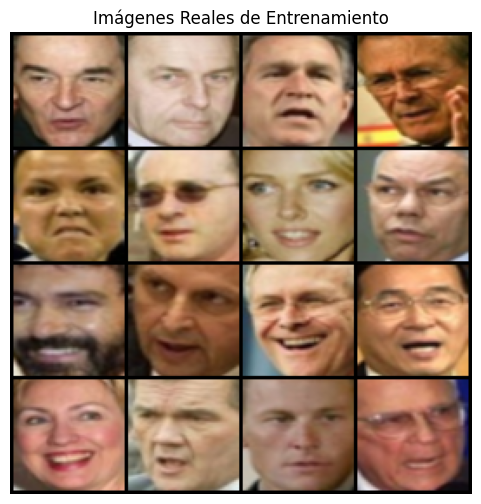

In [2]:
# CELDA 2: Preparación de datos (Rostros humanos LFW redimensionados a 64x64)
print("Descargando y preparando dataset de rostros LFW...")
lfw = fetch_lfw_people(min_faces_per_person=5, resize=0.5, color=True)
images = lfw.images  # Shape: (N, H, W, 3) en rango [0, 1]

# Transformar a tensores de PyTorch, redimensionar a 64x64 y normalizar a [-1, 1]
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

tensor_images = torch.stack([transform((img * 255).astype(np.uint8)) for img in images])
dataset = TensorDataset(tensor_images)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

print(f"Total de imágenes cargadas: {len(tensor_images)} | Forma de batch: {next(iter(dataloader))[0].shape}")

# Visualizar muestras reales
real_batch = next(iter(dataloader))[0][:16]
plt.figure(figsize=(6, 6))
plt.axis("off")
plt.title("Imágenes Reales de Entrenamiento")
plt.imshow(np.transpose(vutils.make_grid(real_batch, nrow=4, padding=2, normalize=True), (1, 2, 0)))
plt.show()

In [3]:
# CELDA 3: Definición de Arquitectura DCGAN (Generator y Discriminator)
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()
        self.net = nn.Sequential(
            # Entrada: Z (LATENT_DIM x 1 x 1) -> (GEN_FEATURES*8 x 4 x 4)
            nn.ConvTranspose2d(LATENT_DIM, GEN_FEATURES * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(GEN_FEATURES * 8),
            nn.ReLU(True),
            # Estado: (GEN_FEATURES*4 x 8 x 8)
            nn.ConvTranspose2d(GEN_FEATURES * 8, GEN_FEATURES * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(GEN_FEATURES * 4),
            nn.ReLU(True),
            # Estado: (GEN_FEATURES*2 x 16 x 16)
            nn.ConvTranspose2d(GEN_FEATURES * 4, GEN_FEATURES * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(GEN_FEATURES * 2),
            nn.ReLU(True),
            # Estado: (GEN_FEATURES x 32 x 32)
            nn.ConvTranspose2d(GEN_FEATURES * 2, GEN_FEATURES, 4, 2, 1, bias=False),
            nn.BatchNorm2d(GEN_FEATURES),
            nn.ReLU(True),
            # Salida: (CHANNELS x 64 x 64)
            nn.ConvTranspose2d(GEN_FEATURES, CHANNELS, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)

class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.net = nn.Sequential(
            # Entrada: (3 x 64 x 64) -> (DISC_FEATURES x 32 x 32)
            nn.Conv2d(CHANNELS, DISC_FEATURES, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # Estado: (DISC_FEATURES*2 x 16 x 16)
            nn.Conv2d(DISC_FEATURES, DISC_FEATURES * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(DISC_FEATURES * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # Estado: (DISC_FEATURES*4 x 8 x 8)
            nn.Conv2d(DISC_FEATURES * 2, DISC_FEATURES * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(DISC_FEATURES * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # Estado: (DISC_FEATURES*8 x 4 x 4)
            nn.Conv2d(DISC_FEATURES * 4, DISC_FEATURES * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(DISC_FEATURES * 8),
            nn.LeakyReLU(0.2, inplace=True),
            # Salida: probabilidad escalar (1 x 1 x 1)
            nn.Conv2d(DISC_FEATURES * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, img):
        return self.net(img).view(-1, 1).squeeze(1)

netG = Generator().to(device)
netD = Discriminator().to(device)
netG.apply(weights_init)
netD.apply(weights_init)
print("Modelos Generator y Discriminator inicializados.")

Modelos Generator y Discriminator inicializados.


In [4]:
# CELDA 4: Entrenamiento Adversarial
criterion = nn.BCELoss()
fixed_noise = torch.randn(16, LATENT_DIM, 1, 1, device=device)

optimizerD = optim.Adam(netD.parameters(), lr=LR, betas=(BETA1, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=LR, betas=(BETA1, 0.999))

G_losses, D_losses = [], []

for epoch in range(EPOCHS):
    for i, (real_imgs,) in enumerate(dataloader):
        real_imgs = real_imgs.to(device)
        b_size = real_imgs.size(0)

        # --- (1) Actualizar Discriminador: maximizar log(D(x)) + log(1 - D(G(z))) ---
        netD.zero_grad()
        label_real = torch.full((b_size,), 0.9, dtype=torch.float, device=device) # Label smoothing
        output_real = netD(real_imgs)
        errD_real = criterion(output_real, label_real)
        errD_real.backward()

        noise = torch.randn(b_size, LATENT_DIM, 1, 1, device=device)
        fake_imgs = netG(noise)
        label_fake = torch.full((b_size,), 0.0, dtype=torch.float, device=device)
        output_fake = netD(fake_imgs.detach())
        errD_fake = criterion(output_fake, label_fake)
        errD_fake.backward()

        errD = errD_real + errD_fake
        optimizerD.step()

        # --- (2) Actualizar Generador: maximizar log(D(G(z))) ---
        netG.zero_grad()
        output_gen = netD(fake_imgs)
        errG = criterion(output_gen, torch.ones_like(output_gen))
        errG.backward()
        optimizerG.step()

        G_losses.append(errG.item())
        D_losses.append(errD.item())

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Época [{epoch+1}/{EPOCHS}] | Loss_D: {errD.item():.4f} | Loss_G: {errG.item():.4f}")

Época [1/30] | Loss_D: 1.0994 | Loss_G: 10.2900
Época [5/30] | Loss_D: 0.9789 | Loss_G: 7.4549
Época [10/30] | Loss_D: 0.7846 | Loss_G: 2.7095
Época [15/30] | Loss_D: 0.7918 | Loss_G: 4.3530
Época [20/30] | Loss_D: 0.8616 | Loss_G: 5.2748
Época [25/30] | Loss_D: 0.7976 | Loss_G: 6.2168
Época [30/30] | Loss_D: 0.6482 | Loss_G: 3.6841


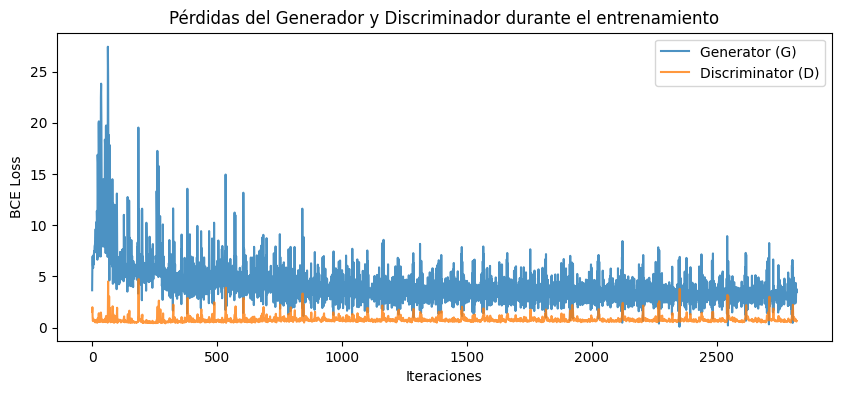

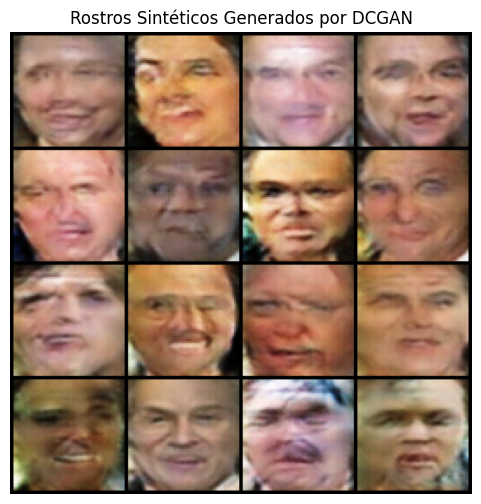

In [5]:
# CELDA 5: Evaluación de Resultados (Curvas de pérdida e imágenes generadas)
plt.figure(figsize=(10, 4))
plt.title("Pérdidas del Generador y Discriminador durante el entrenamiento")
plt.plot(G_losses, label="Generator (G)", alpha=0.8)
plt.plot(D_losses, label="Discriminator (D)", alpha=0.8)
plt.xlabel("Iteraciones")
plt.ylabel("BCE Loss")
plt.legend()
plt.show()

with torch.no_grad():
    fake_samples = netG(fixed_noise).detach().cpu()

plt.figure(figsize=(6, 6))
plt.axis("off")
plt.title("Rostros Sintéticos Generados por DCGAN")
plt.imshow(np.transpose(vutils.make_grid(fake_samples, nrow=4, padding=2, normalize=True), (1, 2, 0)))
plt.show()